In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('dataset.csv', encoding='latin1')
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
5455,ham,Wishing you a beautiful day. Each moment revea...,NaN,NaN,NaN
4288,ham,"Okay, good, no problem, and thanx!",NaN,NaN,NaN
2487,ham,K ill drink.pa then what doing. I need srs mod...,NaN,NaN,NaN
1166,ham,I am not having her number sir,NaN,NaN,NaN
2450,ham,K..give back my thanks.,NaN,NaN,NaN


In [3]:
df.shape

(5572, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


In [5]:
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace=True)

In [6]:
df.sample(5)

,v1,v2
2555,spam,FreeMSG You have been awarded a FREE mini DIGI...
4253,ham,"How about clothes, jewelry, and trips?"
2541,ham,I dont. Can you send it to me. Plus how's mode.
15,spam,"XXXMobileMovieClub: To use your credit, click ..."
5365,spam,Camera - You are awarded a SiPix Digital Camer...


In [7]:
df.rename(columns= {"v1" : "category" , "v2" : "message"}, inplace= True)

In [8]:
df.sample(4)

,category,message
472,ham,Nothing. I meant that once the money enters yo...
5299,ham,Well good morning mr . Hows london treatin' ya...
2585,ham,I will be outside office take all from there
1336,ham,"Sweet, we may or may not go to 4U to meet carl..."


In [9]:
from sklearn.preprocessing import LabelEncoder 
encoder = LabelEncoder()

In [10]:
df['category'] = encoder.fit_transform(df['category'])

df.head()

,category,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [11]:
df.isnull().sum()

category    0
message     0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(403)

In [13]:
df = df.drop_duplicates(keep='first')

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.shape

(5169, 2)

In [16]:
df.head()

,category,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


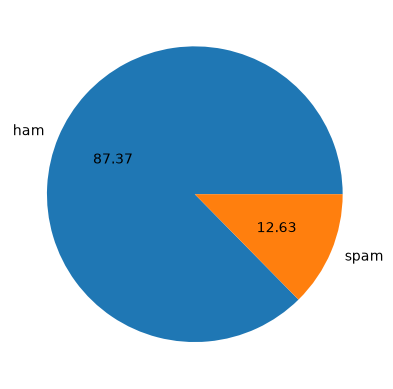

In [17]:
import matplotlib.pyplot as plt
plt.pie(df['category'].value_counts(), labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [18]:
!pip install nltk
import nltk

In [19]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\rites\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [20]:
df['num_characters'] = df['message'].apply(len)

In [21]:

df.head()

,category,message,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [22]:
df['num_words'] = df['message'].apply(lambda x:len(nltk.word_tokenize(x)))

In [23]:
df.head()

,category,message,num_characters,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [24]:
df['num_sentences'] = df['message'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [25]:
df.head()

,category,message,num_characters,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [26]:
!pip install seaborn
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

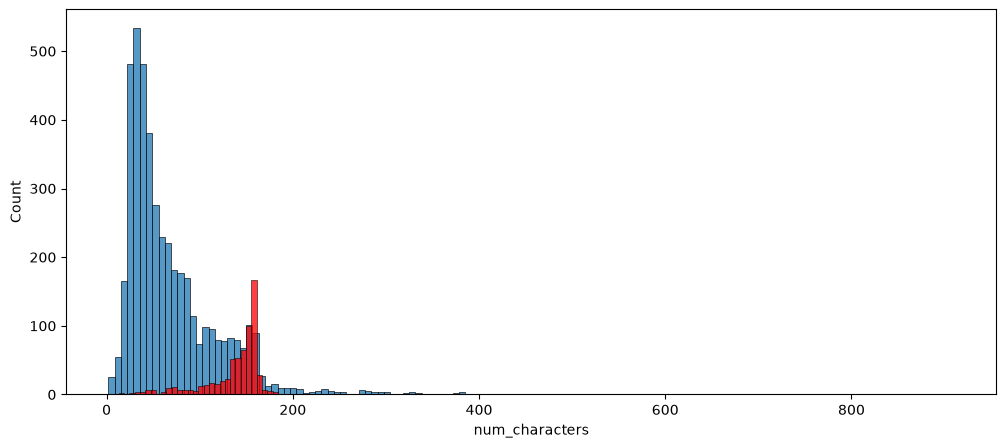

In [27]:
plt.figure(figsize=(12,5))
sns.histplot(df[df['category'] == 0]['num_characters'])
sns.histplot(df[df['category'] == 1]['num_characters'],color='red')

In [28]:
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\rites\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [29]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
ps.stem('joking')

'joke'

In [30]:
import string
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [31]:
def transform_message(message):
    message = message.lower()
    message = nltk.word_tokenize(message)

    y= []
    for i in message:
        if i.isalnum():
            y.append(i)
    message = y[:]
    y.clear()

    for i in message:
        if i not in stop_words and i not in string.punctuation:
            y.append(i)

    message = y[:]
    y.clear()

    for i in message:
        y.append(ps.stem(i))

    return " ".join(y)
            
            
    

In [32]:
transform_message("Hi my name is Ritesh %%")

'hi name ritesh'

In [33]:
df['message'][5]

"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, å£1.50 to rcv"

In [34]:
df['transformed_message'] = df['message'].apply(transform_message)

In [35]:
df.columns

Index(['category', 'message', 'num_characters', 'num_words', 'num_sentences',
       'transformed_message'],
      dtype='str')

In [36]:
!pip install wordcloud
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=12,background_color='grey')

In [37]:
wc = WordCloud(
    width=500,
    height=500,
    min_font_size=12,
    background_color='white'
)

In [38]:

spam_wc = wc.generate(df[df['category'] == 1]['transformed_message'].str.cat(sep=" "))

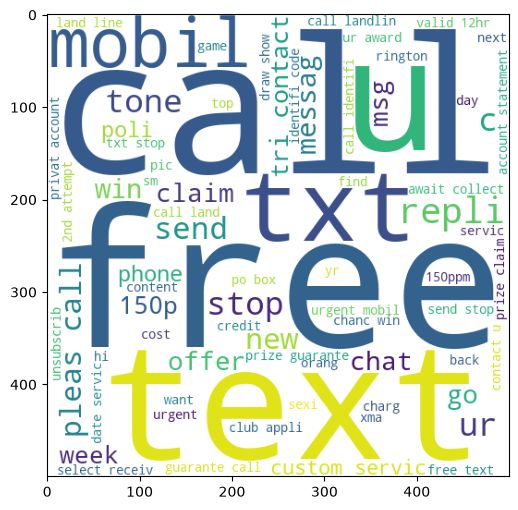

In [39]:
plt.figure(figsize=(15,6))
plt.imshow(spam_wc)

In [40]:
ham_wc = wc.generate(df[df['category'] == 0]['transformed_message'].str.cat(sep=" "))

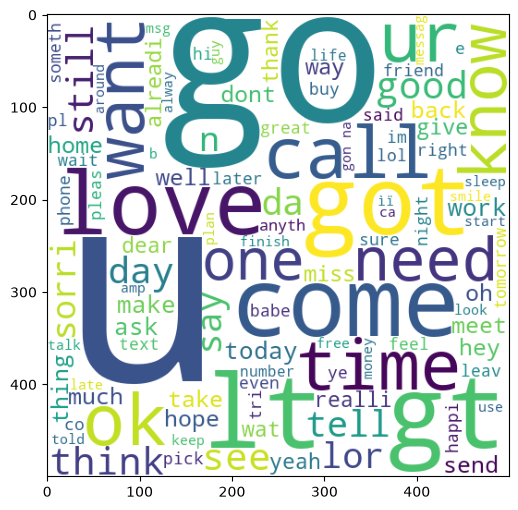

In [41]:
plt.figure(figsize=(15,6))
plt.imshow(ham_wc)

In [42]:
df.head()

,category,message,num_characters,num_words,num_sentences,transformed_message
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=3000)

In [44]:
X = tfidf.fit_transform(df['transformed_message']).toarray()

In [45]:
y = df['category'].values

In [46]:
from sklearn.model_selection import train_test_split

In [47]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [48]:
from sklearn.naive_bayes import MultinomialNB
mnb = MultinomialNB()
mnb.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3620., 515.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.13,-2.08]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 3000)","[[ 0. , 0. , 0. ,..., 0. , 0.38,16.22], [ 0.35, 0.81, 0.9 ,..., 1.07, 0. , 0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 3000)","[[-9.34,-9.34,-9.34,...,-9.34,-9.02,-6.5 ], [-8.16,-7.86,-7.82,...,-7.73,-8.46,-8.46]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3000


In [49]:
y_pred = mnb.predict(X_test)

In [50]:
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))

Accuracy: 0.9709864603481625
Precision: 1.0


In [51]:
print(confusion_matrix(y_test, y_pred))

[[896   0]
 [ 30 108]]


In [52]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))

Accuracy: 0.9545454545454546
Precision: 0.9789473684210527


In [53]:
from sklearn.svm import SVC

svc = SVC(kernel='linear')
svc.fit(X_train, y_train)

y_pred_svc = svc.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_svc))
print("Precision:", precision_score(y_test, y_pred_svc))

Accuracy: 0.9787234042553191
Precision: 0.9754098360655737


In [54]:
import pickle
pickle.dump(mnb, open('model.pkl', 'wb'))

In [55]:
pickle.dump(tfidf, open('vectorizer.pkl', 'wb'))

In [56]:
model = pickle.load(open('model.pkl', 'rb'))
vectorizer = pickle.load(open('vectorizer.pkl', 'rb'))

In [57]:
message = ["Congratulations! You have won a free prize. Click now!"]

transformed = vectorizer.transform(message)

prediction = model.predict(transformed)

prediction

if prediction[0] == 1:
    print("Spam")
else:
    print("Not Spam")

Spam
